# Agente de calidad del aire del Valle de Aburrá
**SI3003 – Inteligencia Artificial · Proyecto final · EAFIT 2026-1**

Este cuaderno recorre el proyecto paso a paso: los datos, la **Parte 1** (HMM y Naive Bayes escritos desde cero, comparados con una línea base) y la **Parte 2** (agente con RAG y herramientas). El código vive en la carpeta `src/`; aquí solo se usa y se muestran los resultados.

> Se ejecuta desde la carpeta `notebooks/`. Las celdas de la Parte 2 necesitan la variable `NVIDIA_API_KEY` (mira el README).

In [1]:
# Preparar: importar las librerías y el código del proyecto (carpeta src/)
import sys
sys.path.insert(0, "..")                       # para poder importar la carpeta src desde notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config as cfg
from src.datos import cargar_series, armar_tabla, split_temporal, metricas, nombre_categoria
from src.modelos import NaiveBayesCategorico, HMMGaussiano

plt.rcParams["figure.figsize"] = (11, 4)

## 1. Datos
Son archivos de PM2.5 diario descargados de **SISAIRE** (plan B del enunciado: históricos descargados). Se usan 4 estaciones de Medellín. *Almacén EPM* se descartó porque su serie empieza en diciembre de 2023.

La limpieza (en `src/datos.py`): se quitan filas sin fecha y duplicados, se arma un calendario diario completo, los PM2.5 iguales a cero se tratan como falla del sensor, y los huecos de hasta 3 días se rellenan con el último valor conocido (solo mira el pasado). Los huecos largos se dejan vacíos.

In [2]:
# Cargar las series (si no existe data/processed/pm25_diario.csv, se crea a partir de los .xls)
series = cargar_series()
resumen = pd.DataFrame({
    "días con dato": {e: int(s.notna().sum()) for e, s in series.items()},
    "días sin dato": {e: int(s.isna().sum()) for e, s in series.items()},
    "PM2.5 promedio": {e: round(s.mean(), 1) for e, s in series.items()},
})
resumen

,días con dato,días sin dato,PM2.5 promedio
Parque Biblioteca,2828,2,15.6
Santa Elena,2784,46,9.2
Tráfico Centro,2827,3,25.6
Villahermosa,2830,0,16.5


### Exploración
Las categorías son: **Buena** (≤12 µg/m³), **Moderada** (12–37) y **Alerta** (>37). Las líneas punteadas marcan esos umbrales.

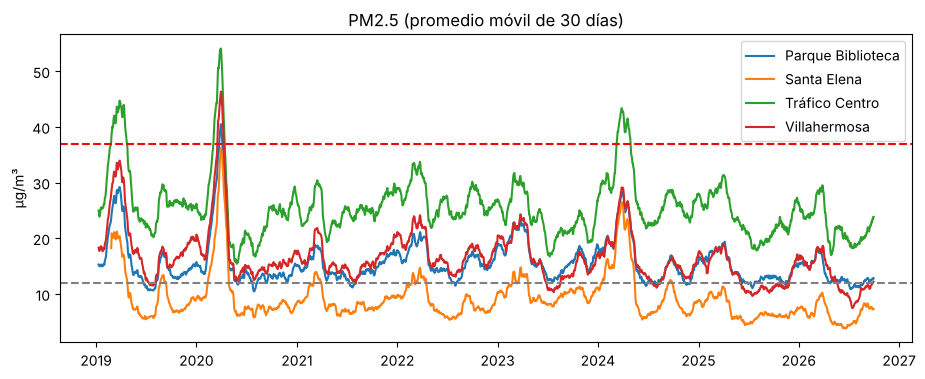

In [3]:
# Gráfica 1: PM2.5 de cada estación (promedio móvil de 30 días)
fig, ax = plt.subplots()
for est, s in series.items():
    ax.plot(s.index, s.rolling(30, min_periods=10).mean(), label=est)
ax.axhline(12, ls="--", c="gray"); ax.axhline(37, ls="--", c="red")
ax.set_title("PM2.5 (promedio móvil de 30 días)"); ax.set_ylabel("µg/m³"); ax.legend()
plt.show()

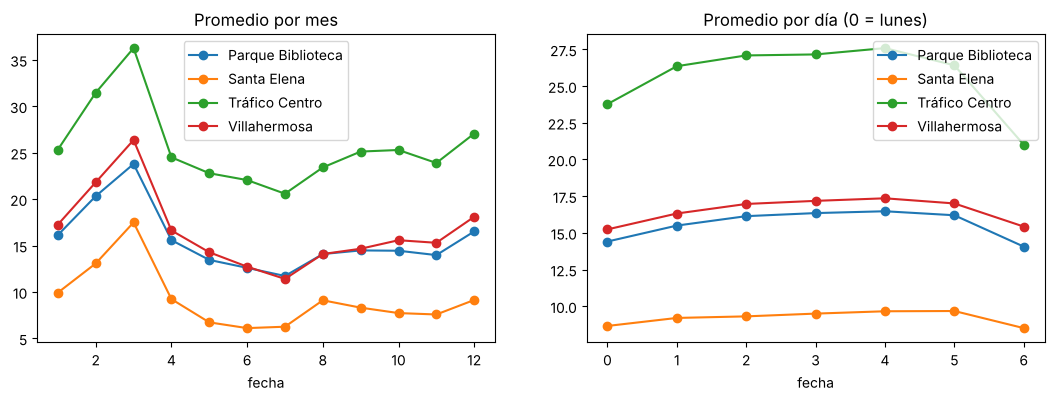

In [4]:
# Gráfica 2: promedio por mes y por día de la semana
df = pd.DataFrame(series)
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
df.groupby(df.index.month).mean().plot(ax=axs[0], marker="o", title="Promedio por mes")
df.groupby(df.index.dayofweek).mean().plot(ax=axs[1], marker="o", title="Promedio por día (0 = lunes)")
plt.show()

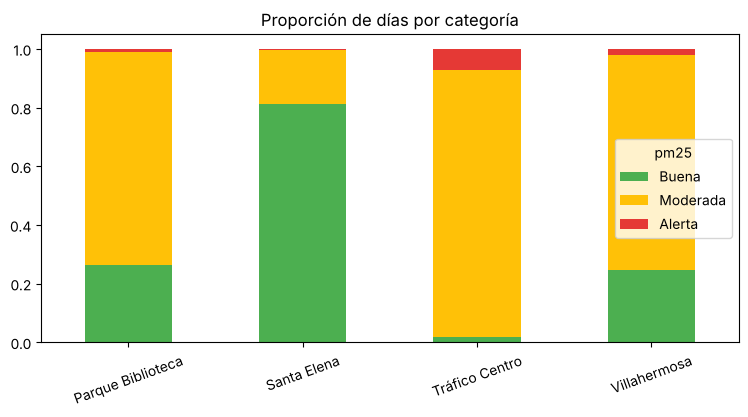

pm25,Buena,Moderada,Alerta
Parque Biblioteca,0.262,0.726,0.011
Santa Elena,0.814,0.181,0.005
Tráfico Centro,0.018,0.910,0.072
Villahermosa,0.246,0.735,0.020


In [5]:
# Gráfica 3: proporción de días por categoría en cada estación
prop = pd.DataFrame({e: pd.cut(s.dropna(), [0, 12, 37, np.inf], labels=cfg.CLASES).value_counts(normalize=True)
                     for e, s in series.items()}).T[cfg.CLASES]
prop.plot(kind="bar", stacked=True, color=["#4caf50", "#ffc107", "#e53935"], figsize=(9, 4))
plt.title("Proporción de días por categoría"); plt.xticks(rotation=20); plt.show()
prop.round(3)

## 2. Parte 1: predecir la categoría de mañana
**Objetivo:** dado cómo estuvo el aire hoy, predecir la categoría de mañana. Se entrena con 2019–2025 y se prueba con 2026, que el modelo nunca ve al entrenar. Las pistas se eligen con 2025 como validación (script `scripts/evaluar_modelos.py`).

- **Línea base:** "mañana = hoy".
- **Naive Bayes** (desde cero): cuenta, en el pasado, qué pasó mañana en situaciones parecidas (hoy, ayer, día y mes).
- **HMM** (desde cero): descubre estados ocultos del aire que duran días; su estado se usa como una pista más.

In [6]:
# Dividir en entrenamiento (antes de 2026) y prueba (2026), y ver cuántos días hay de cada clase
datos = {}
for est, s in series.items():
    train, test = split_temporal(armar_tabla(s))
    datos[est] = {"train": train.copy(), "test": test.copy()}
    print(f"{est}: train={len(train)} | test={len(test)} | clases en train={np.bincount(train['y'].astype(int), minlength=3)} "
          f"| clases en test={np.bincount(test['y'].astype(int), minlength=3)}")

Parque Biblioteca: train=2552 | test=272 | clases en train=[ 639 1881   32] | clases en test=[101 171   0]
Santa Elena: train=2510 | test=272 | clases en train=[2007  488   15] | clases en test=[258  14   0]
Tráfico Centro: train=2551 | test=272 | clases en train=[  36 2314  201] | clases en test=[ 15 254   3]
Villahermosa: train=2556 | test=272 | clases en train=[ 555 1945   56] | clases en test=[139 133   0]


In [7]:
# Línea base: la predicción de mañana es la categoría de hoy
filas = []
for est, d in datos.items():
    m = metricas(d["test"]["y"], d["test"]["cat_hoy"])
    filas.append({"estacion": est, "modelo": "Línea base", "accuracy": m["accuracy"], "f1_macro_presentes": m["f1_macro_presentes"]})
pd.DataFrame(filas).round(3)

,estacion,modelo,accuracy,f1_macro_presentes
0,Parque Biblioteca,Línea base,0.706,0.685
1,Santa Elena,Línea base,0.926,0.623
2,Tráfico Centro,Línea base,0.926,0.587
3,Villahermosa,Línea base,0.739,0.740


In [8]:
# HMM: entrenar uno por estación con el pasado y ver qué estados descubrió
hmms = {}
for est, s in series.items():
    obs = np.log1p(s.to_numpy())
    n_train = int((s.index < cfg.FECHA_CORTE).sum())
    hmms[est] = HMMGaussiano(n_estados=3).fit(obs[:n_train])
    print(f"{est}: PM2.5 típico de cada estado = {np.round(np.expm1(hmms[est].mu), 1)} | "
          f"prob. de quedarse en el mismo estado = {np.round(np.diag(hmms[est].A), 2)}")

Parque Biblioteca: PM2.5 típico de cada estado = [12.  16.9 28.2] | prob. de quedarse en el mismo estado = [0.92 0.88 0.91]


Santa Elena: PM2.5 típico de cada estado = [ 6.1 10.2 23. ] | prob. de quedarse en el mismo estado = [0.95 0.9  0.88]


Tráfico Centro: PM2.5 típico de cada estado = [19.2 26.3 41.2] | prob. de quedarse en el mismo estado = [0.91 0.94 0.93]


Villahermosa: PM2.5 típico de cada estado = [12.  17.5 31.5] | prob. de quedarse en el mismo estado = [0.94 0.93 0.9 ]


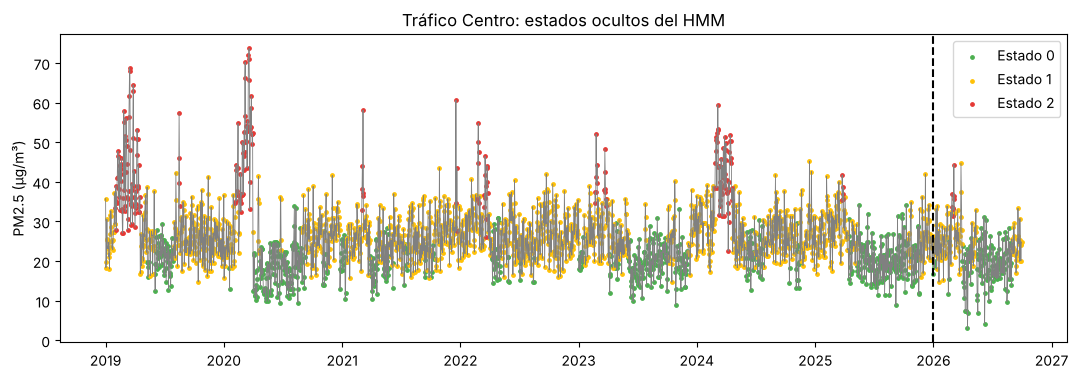

In [9]:
# Gráfica de los estados ocultos del HMM (Tráfico Centro)
est = "Tráfico Centro"
s = series[est]
estados = hmms[est].viterbi(np.log1p(s.to_numpy()))
colores = ["#4caf50", "#ffc107", "#e53935"]
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(s.index, s.values, color="gray", lw=0.6)
for k in range(3):
    ax.scatter(s.index[estados == k], s.values[estados == k], s=6, color=colores[k], label=f"Estado {k}")
ax.axvline(pd.Timestamp(cfg.FECHA_CORTE), ls="--", c="black")       # desde aquí es la prueba
ax.set_title(f"{est}: estados ocultos del HMM"); ax.set_ylabel("PM2.5 (µg/m³)"); ax.legend()
plt.show()

### Resultados de la validación y de la prueba
Los genera `python scripts/evaluar_modelos.py` y quedan en `results/`. En la validación (2025) ninguna combinación de pistas superó a la línea base; se usó la configuración **F** (hoy, ayer, estado del HMM, día y mes), que quedó prácticamente igual.

In [10]:
# Validación con 2025: promedio de las estaciones
pd.read_csv("../results/validacion_pistas.csv", index_col=0)

,accuracy,f1_presentes
config,,
Línea base,0.826,0.567
F: hoy+ayer+HMM+dia+mes,0.827,0.562
G: hoy+HMM+mes,0.820,0.554
D: hoy+ayer+HMM,0.826,0.552
E: hoy+ayer+HMM+mes,0.816,0.552
C: hoy+ayer+dia+mes,0.829,0.550
B: hoy+ayer+mes,0.825,0.543
A: hoy+ayer,0.827,0.503


In [11]:
# Evaluación en 2026: línea base, Naive Bayes y Naive Bayes + HMM
res = pd.read_csv("../results/metricas_modelos.csv")
display(res)
res.groupby("modelo", sort=False)[["accuracy", "f1_macro_3clases", "f1_macro_presentes"]].mean().round(3)

,estacion,modelo,accuracy,f1_macro_3clases,f1_macro_presentes,dias_prueba,dias_alerta_prueba
0,Parque Biblioteca,Línea base (mañana = hoy),0.706,0.457,0.685,272,0
1,Parque Biblioteca,Naive Bayes,0.680,0.428,0.642,272,0
2,Parque Biblioteca,Naive Bayes + HMM,0.699,0.452,0.678,272,0
3,Santa Elena,Línea base (mañana = hoy),0.926,0.416,0.623,272,0
4,Santa Elena,Naive Bayes,0.930,0.450,0.675,272,0
5,Santa Elena,Naive Bayes + HMM,0.923,0.441,0.661,272,0
6,Tráfico Centro,Línea base (mañana = hoy),0.926,0.587,0.587,272,3
7,Tráfico Centro,Naive Bayes,0.923,0.519,0.519,272,3
8,Tráfico Centro,Naive Bayes + HMM,0.908,0.494,0.494,272,3
9,Villahermosa,Línea base (mañana = hoy),0.739,0.493,0.740,272,0


,accuracy,f1_macro_3clases,f1_macro_presentes
modelo,,,
Línea base (mañana = hoy),0.824,0.488,0.659
Naive Bayes,0.816,0.471,0.642
Naive Bayes + HMM,0.819,0.471,0.645


**Lectura de los resultados.** El modelo **empata con la línea base** (accuracy 0.819 contra 0.824). Es esperable: el PM2.5 cambia despacio de un día al siguiente, así que "mañana = hoy" ya acierta mucho. Además hay muy pocos días de *Alerta* en 2026 (0 en tres estaciones), por lo que el F1 de esa clase no se puede medir bien. El HMM sí aporta valor interpretativo: encuentra regímenes de contaminación que duran días.

## 3. Parte 2: agente con RAG y herramientas
El agente usa un modelo de lenguaje de NVIDIA (API compatible con OpenAI) y **tres herramientas**:

1. `obtener_pm25`: PM2.5 medido en una estación y fecha.
2. `predecir_manana`: categoría prevista para el día siguiente (el modelo de la Parte 1).
3. `buscar_documentos`: búsqueda (RAG con embeddings y FAISS) en la Resolución 2254 de 2017, informes del AMVA/SIATA y las directrices de la OMS 2021, con citas de fuente y página.

El loop tiene un máximo de vueltas y de consultas, los errores de las herramientas vuelven al modelo como observación, y hay un plan de respaldo si el modelo devuelve una respuesta vacía.

> **Las celdas siguientes necesitan `NVIDIA_API_KEY`** (y la primera vez descargan el modelo de embeddings, ~470 MB). Si trabajas en Colab: `import os; from google.colab import userdata; os.environ["NVIDIA_API_KEY"] = userdata.get("NVIDIA_API_KEY")`.

In [ ]:
# Probar el buscador de documentos (RAG): ¿encuentra la norma?
from src.rag import buscar_documentos
r = buscar_documentos("¿Cuál es el nivel máximo permisible de PM2.5 en 24 horas?", k=3)
for f in r["fragmentos"]:
    print(f"[{f['similitud']}] {f['fuente']} | pág. {f['pagina']}\n   {f['texto'][:200]}...\n")

In [ ]:
# Preguntarle al agente: una pregunta de datos, una de predicción, una de normas y una fuera de alcance
from src.agente import preguntar_agente
for pregunta in ["¿Cómo está el aire hoy en Santa Elena?",
                 "¿Cómo estará mañana en Tráfico Centro?",
                 "¿Cuáles son los niveles de prevención, alerta y emergencia para PM2.5?",
                 "¿De qué colores es la bandera de Colombia?"]:
    print("\nPregunta:", pregunta)
    respuesta, _, usadas = preguntar_agente(pregunta)
    print("Respuesta:", respuesta, "| herramientas:", usadas)

### Evaluación del agente
`python scripts/evaluar_agente.py` ejecuta **15 preguntas fijas** (datos, predicción, documentos, una combinada, errores, seguridad y tres fuera de alcance) y guarda `results/evaluacion_agente.csv`: si usó la herramienta correcta, si citó la fuente, si el contenido es correcto y si hay citas falsas. La revisión automática solo busca cifras y palabras clave, por eso el archivo incluye la columna `revision_manual` para anotar la lectura a mano.

In [ ]:
# Ver la evaluación del agente (si ya se ejecutó el script)
from pathlib import Path
ruta = Path("../results/evaluacion_agente.csv")
if ruta.exists():
    ev = pd.read_csv(ruta)
    display(ev[["n", "tipo", "pregunta", "herramienta_correcta", "cito_fuente", "contenido_correcto", "cita_falsa"]])
else:
    print("Todavía no existe results/evaluacion_agente.csv: ejecuta  python scripts/evaluar_agente.py")

## 4. Dashboard
Se abre con `python app.py` (en `http://127.0.0.1:7860`) o desde aquí. Tiene selector de estación y fecha, mapa, serie de tiempo con los estados del HMM, comparación entre estaciones, predicción de mañana y el chat con el agente.

In [ ]:
# Abrir el dashboard (al terminar, detén la celda con el botón de parar)
from src.dashboard import lanzar
lanzar(share=False)